# 1. Load Libraries and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import math

from pathlib import Path
from rasterio.windows import from_bounds, Window

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

%matplotlib inline

plt.rcParams.update({
    "font.size": 13,
    "figure.dpi": 120
})

ROOT = Path.cwd().resolve()

if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
OUTPUT_DIR = DATA_DIR / "derived"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "Emissivity": DATA_DIR / "Venus_Magellan_MicrowaveEmissivity_Global_4641m.tif",
    "Reflectivity": DATA_DIR / "Venus_Magellan_FresnelReflectivity_Global_4641m.tif",
    "RMS_Slope": DATA_DIR / "Venus_Magellan_MeterScaleSlope_Global_4641m.tif",
    "Topography": DATA_DIR / "Venus_Magellan_Topography_Global_4641m_v02.tif",
    "SAR_Brightness": DATA_DIR / "Venus_Magellan_C3-MDIR_Global_Mosaic_2025m.tif"
}

for name, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(path)

print("All five datasets found.")

All five datasets found.


# 2. Fibonaccii lat_long

In [18]:
# Global sampling parameters

N_SAMPLES = 20000
VENUS_RADIUS = 6051000.0


def fibonacci_sphere(n):

    i = np.arange(n)

    # Equally spaced in sin(latitude)
    z = 1 - 2 * (i + 0.5) / n

    lat = np.rad2deg(np.arcsin(z))

    # Golden-angle longitude
    golden_angle = np.pi * (3 - np.sqrt(5))

    lon = np.rad2deg(i * golden_angle)

    # Convert longitude to [-180, 180]
    lon = (lon + 180) % 360 - 180

    return pd.DataFrame({
        "Sample_ID": i,
        "Longitude": lon,
        "Latitude": lat
    })


df_global = fibonacci_sphere(N_SAMPLES)

display(df_global.head())
print("Total locations:", len(df_global))

,Sample_ID,Longitude,Latitude
0,0,0.000000,89.427040
1,1,137.507764,89.007596
2,2,-84.984472,88.718801
3,3,52.523292,88.484052
4,4,-169.968944,88.281062


Total locations: 20000


# 3. Visualize the sampling distribution

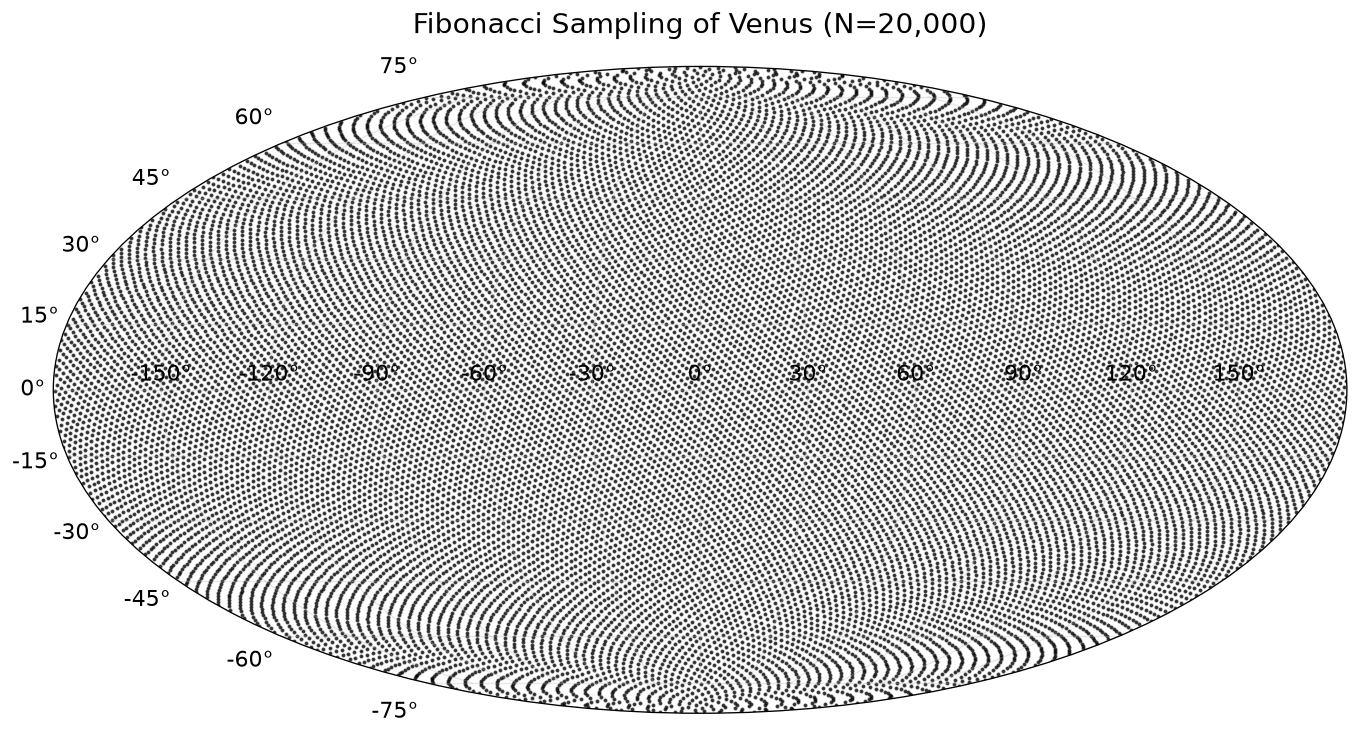

In [19]:
fig = plt.figure(figsize=(15, 7))

ax = fig.add_subplot(111, projection="mollweide")

ax.scatter(
    np.deg2rad(df_global["Longitude"]),
    np.deg2rad(df_global["Latitude"]),
    s=2,
    color="black",
    alpha=0.65,
    rasterized=True
)

ax.grid(alpha=0.3)
ax.set_title(
    f"Fibonacci Sampling of Venus (N={N_SAMPLES:,})",
    fontsize=17,
    pad=20
)

plt.show()

# Extract the Magellan measurements

## 4 — Extract a footprint-averaged value

In [20]:
# Approximate projected sampling window
FOOTPRINT_KM = 60

# Minimum valid coverage within each window
MIN_VALID_FRACTION = 0.70


def sample_footprint_means(
    dataset_name,
    locations,
    footprint_km=60,
    min_valid_fraction=0.70
):

    path = FILES[dataset_name]

    half_width = footprint_km * 1000 / 2

    output = np.full(
        len(locations),
        np.nan,
        dtype=np.float64
    )

    with rasterio.open(path) as src:

        scale = src.scales[0]
        offset = src.offsets[0]

        for i, (lon, lat) in enumerate(
            locations[["Longitude", "Latitude"]]
            .itertuples(index=False, name=None)
        ):

            # Geographic degrees -> Venus projected meters
            x = VENUS_RADIUS * np.deg2rad(lon)
            y = VENUS_RADIUS * np.deg2rad(lat)

            # Sampling window in projected coordinates
            w = from_bounds(
                left=x - half_width,
                bottom=y - half_width,
                right=x + half_width,
                top=y + half_width,
                transform=src.transform
            )

            # Expand to integer pixel boundaries
            col0 = math.floor(w.col_off)
            row0 = math.floor(w.row_off)

            col1 = math.ceil(w.col_off + w.width)
            row1 = math.ceil(w.row_off + w.height)

            # Skip windows crossing raster boundaries
            if (
                col0 < 0 or row0 < 0 or
                col1 > src.width or
                row1 > src.height
            ):
                continue

            window = Window(
                col_off=col0,
                row_off=row0,
                width=col1 - col0,
                height=row1 - row0
            )

            raw = src.read(
                1,
                window=window,
                masked=True
            ).astype(np.float64)

            raw = np.ma.filled(raw, np.nan)

            # Additional missing-data codes
            if dataset_name in [
                "Emissivity",
                "Reflectivity",
                "RMS_Slope"
            ]:
                raw[raw == 0] = np.nan

            elif dataset_name == "Topography":
                raw[raw == -32768] = np.nan

            valid = np.isfinite(raw)

            if valid.mean() < min_valid_fraction:
                continue

            raw_mean = np.nanmean(raw)

            # Use original PDS slope conversion
            if dataset_name == "RMS_Slope":
                value = (raw_mean - 1) / 10

            else:
                value = raw_mean * scale + offset

            output[i] = value

    return output

## 5 - extract all 5 datasetS

In [21]:
for name in FILES:

    print(f"Extracting {name}...")

    df_global[name] = sample_footprint_means(
        name,
        df_global,
        footprint_km=FOOTPRINT_KM,
        min_valid_fraction=MIN_VALID_FRACTION
    )

    n_valid = df_global[name].notna().sum()

    print(
        f"  Valid observations: "
        f"{n_valid:,}/{len(df_global):,}"
    )

print("\nExtraction complete.")

display(df_global.head())

Extracting Emissivity...
  Valid observations: 19,321/20,000
Extracting Reflectivity...
  Valid observations: 19,018/20,000
Extracting RMS_Slope...
  Valid observations: 19,405/20,000
Extracting Topography...
  Valid observations: 19,414/20,000
Extracting SAR_Brightness...
  Valid observations: 19,393/20,000

Extraction complete.


,Sample_ID,Longitude,Latitude,Emissivity,Reflectivity,RMS_Slope,Topography,SAR_Brightness
0,0,0.000000,89.427040,0.847204,NaN,NaN,NaN,134.417204
1,1,137.507764,89.007596,0.844197,NaN,NaN,NaN,NaN
2,2,-84.984472,88.718801,0.852301,NaN,NaN,NaN,132.784946
3,3,52.523292,88.484052,0.843531,NaN,NaN,NaN,NaN
4,4,-169.968944,88.281062,0.853646,NaN,NaN,NaN,141.622581


## Validate and save dataset

In [22]:
# Basic physical-range checks
# These are screening limits, not uncertainty filters.

physical_limits = {
    "Emissivity": (0, 1),
    "Reflectivity": (0, 1),
    "RMS_Slope": (0, 90)
}

for name, (low, high) in physical_limits.items():

    invalid = (
        (df_global[name] < low) |
        (df_global[name] > high)
    )

    print(f"{name}: {invalid.sum()} out-of-range values")

    df_global.loc[invalid, name] = np.nan


# Summary
display(
    df_global[
        list(FILES.keys())
    ].describe().round(4)
)

print("\nMissing data percentage:")

display(
    (
        df_global[list(FILES.keys())]
        .isna()
        .mean()
        .mul(100)
    ).round(2)
)

# Save complete dataset, retaining NaNs
df_global.to_csv(
    OUTPUT_DIR / "venus_fibonacci_10000.csv",
    index=False
)

Emissivity: 0 out-of-range values
Reflectivity: 0 out-of-range values
RMS_Slope: 0 out-of-range values


,Emissivity,Reflectivity,RMS_Slope,Topography,SAR_Brightness
count,19321.0000,19018.0000,19405.0000,19414.0000,19393.0000
mean,0.8450,0.1283,2.8553,884.2654,131.0512
std,0.0443,0.0548,1.1454,952.6179,19.4512
min,0.3340,0.0341,0.3362,-1220.2500,54.7419
25%,0.8324,0.0947,2.1026,292.0459,118.4677
50%,0.8500,0.1132,2.6791,683.3929,129.1731
75%,0.8670,0.1423,3.3638,1218.8393,141.6602
max,0.9444,0.7186,10.0444,10335.9082,220.7056



Missing data percentage:


Emissivity        3.40
Reflectivity      4.91
RMS_Slope         2.97
Topography        2.93
SAR_Brightness    3.03
dtype: float64

# Build the global three-dimensional clustering dataset

## 7 — Select features and standardize

In [23]:
CLUSTER_FEATURES = [
    "Emissivity",
    "Reflectivity",
    "RMS_Slope"
]

# Keep locations with complete clustering features
df_train = (
    df_global
    .dropna(subset=CLUSTER_FEATURES)
    .copy()
    .reset_index(drop=True)
)

X = df_train[CLUSTER_FEATURES].to_numpy()

scaler_global = StandardScaler()

X_scaled = scaler_global.fit_transform(X)

print("Clustering features:", CLUSTER_FEATURES)
print("Input matrix:", X_scaled.shape)

Clustering features: ['Emissivity', 'Reflectivity', 'RMS_Slope']
Input matrix: (18603, 3)


# Ward hierarchical clustering and the global dendrogram

## Cell 8 — Fit Ward hierarchical clustering

In [24]:
from scipy.cluster.hierarchy import linkage

print("Starting global Ward clustering...")

Z_global = linkage(
    X_scaled,
    method="ward",
    metric="euclidean",
    optimal_ordering=False
)

print("Ward clustering completed.")
print("Linkage matrix shape:", Z_global.shape)

Starting global Ward clustering...
Ward clustering completed.
Linkage matrix shape: (18602, 4)


## 9 — Plot the global dendrogram

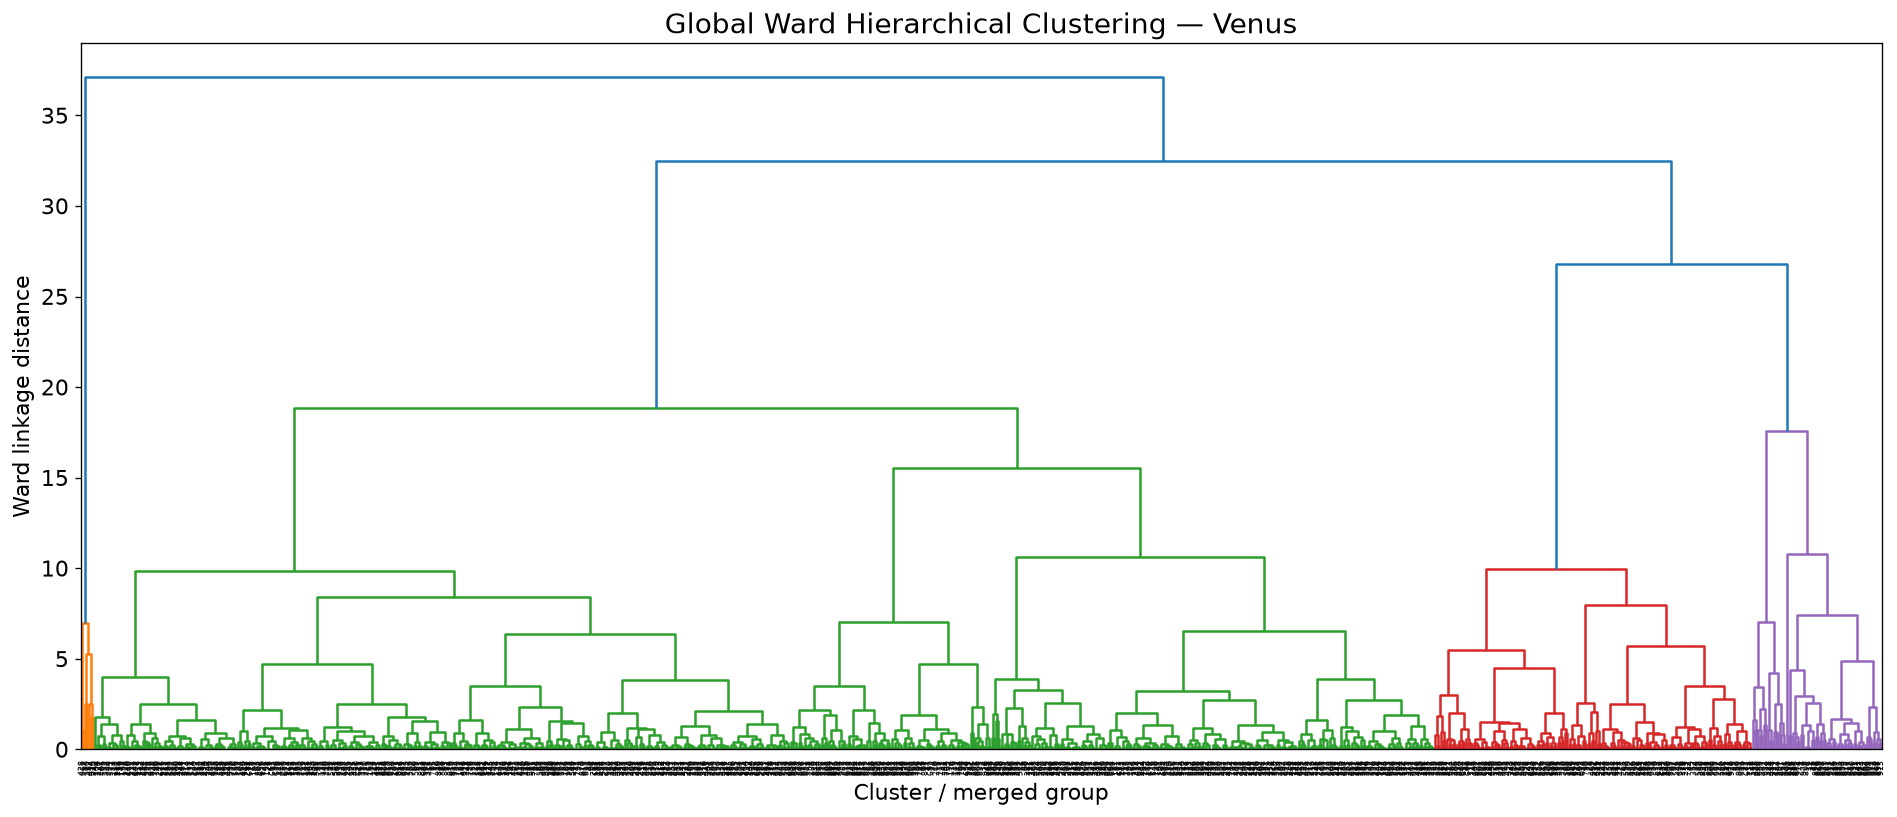

In [11]:
fig, ax = plt.subplots(figsize=(16, 7))

dendrogram(
    Z_global,
    truncate_mode="lastp",
    p=0,
    show_leaf_counts=True,
    show_contracted=True,
    ax=ax
)

ax.set_title(
    "Global Ward Hierarchical Clustering — Venus",
    fontsize=17
)

ax.set_xlabel("Cluster / merged group")
ax.set_ylabel("Ward linkage distance")

plt.tight_layout()
plt.show()

## 10 — Select your cluster count

In [12]:
# Cell 10 — Ward clustering using a distance threshold

from scipy.cluster.hierarchy import fcluster

# Set the Ward linkage distance threshold
CUT_DISTANCE = 5.0  # Example only; adjust based on your dendrogram

# Cut the dendrogram at the specified distance
labels_ward = fcluster(
    Z_global,
    t=CUT_DISTANCE,
    criterion="distance"
)

# Convert labels to 0-based indexing
labels_ward = labels_ward - 1

# Number of clusters identified automatically
K = len(np.unique(labels_ward))

df_train["Ward_Cluster"] = labels_ward

print(f"Cut distance: {CUT_DISTANCE:.2f}")
print(f"Number of clusters identified: {K}")

print("\nCluster populations:")
display(
    df_train["Ward_Cluster"]
    .value_counts()
    .sort_index()
)

Cut distance: 5.00
Number of clusters identified: 22

Cluster populations:


Ward_Cluster
0       2
1       2
2       3
3      75
4     112
5      75
6     102
7      53
8      52
9      61
10     99
11     72
12     20
13     50
14     17
15     35
16     44
17      8
18     10
19     20
20     29
21      1
Name: count, dtype: int64

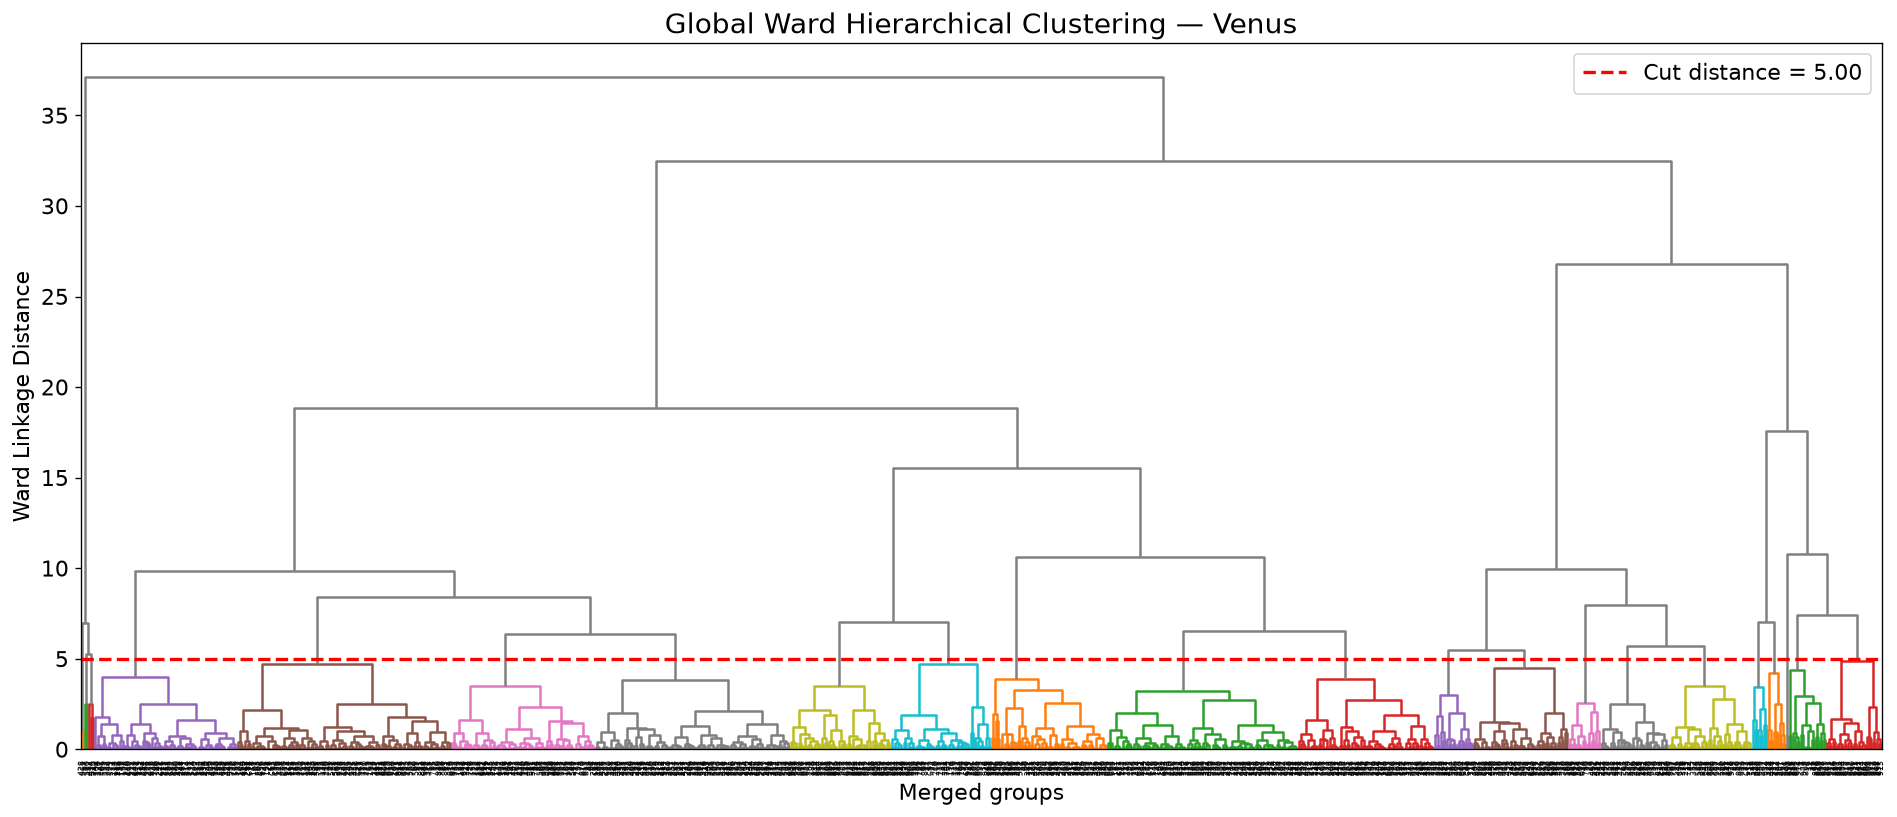

In [14]:
# Cell 9 — Global Ward dendrogram with distance cutoff

from scipy.cluster.hierarchy import dendrogram

# Set the threshold here
CUT_DISTANCE = 5.0  # Replace with your chosen merge distance

fig, ax = plt.subplots(figsize=(16, 7))

dendrogram(
    Z_global,
    truncate_mode="lastp",
    p=0,
    show_leaf_counts=True,
    show_contracted=True,
    color_threshold=CUT_DISTANCE,
    above_threshold_color="gray",
    ax=ax
)

# Show dendrogram cut
ax.axhline(
    y=CUT_DISTANCE,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Cut distance = {CUT_DISTANCE:.2f}"
)

ax.set_title(
    "Global Ward Hierarchical Clustering — Venus",
    fontsize=17
)

ax.set_xlabel("Merged groups")
ax.set_ylabel("Ward Linkage Distance")

ax.legend()

plt.tight_layout()
plt.show()

# Fit a global GMM using the same data

## 11 — Global GMM

In [15]:
gmm_global = GaussianMixture(
    n_components=K,
    covariance_type="full",
    n_init=10,
    reg_covar=1e-5,
    random_state=42,
    max_iter=500
)

labels_gmm = gmm_global.fit_predict(X_scaled)

df_train["GMM_Cluster"] = labels_gmm

df_train["GMM_Probability"] = (
    gmm_global.predict_proba(X_scaled).max(axis=1)
)

print("GMM cluster populations:")
display(
    df_train["GMM_Cluster"]
    .value_counts()
    .sort_index()
)

ari = adjusted_rand_score(
    labels_ward,
    labels_gmm
)

print(f"\nWard vs. GMM ARI: {ari:.3f}")

GMM cluster populations:


GMM_Cluster
0      50
1      40
2       4
3       3
4      55
5      50
6      50
7      13
8      91
9      80
10     84
11      7
12    103
13      1
14     17
15    109
16      5
17     25
18      2
19      2
20     28
21    123
Name: count, dtype: int64


Ward vs. GMM ARI: 0.332


# Generate the global cluster maps

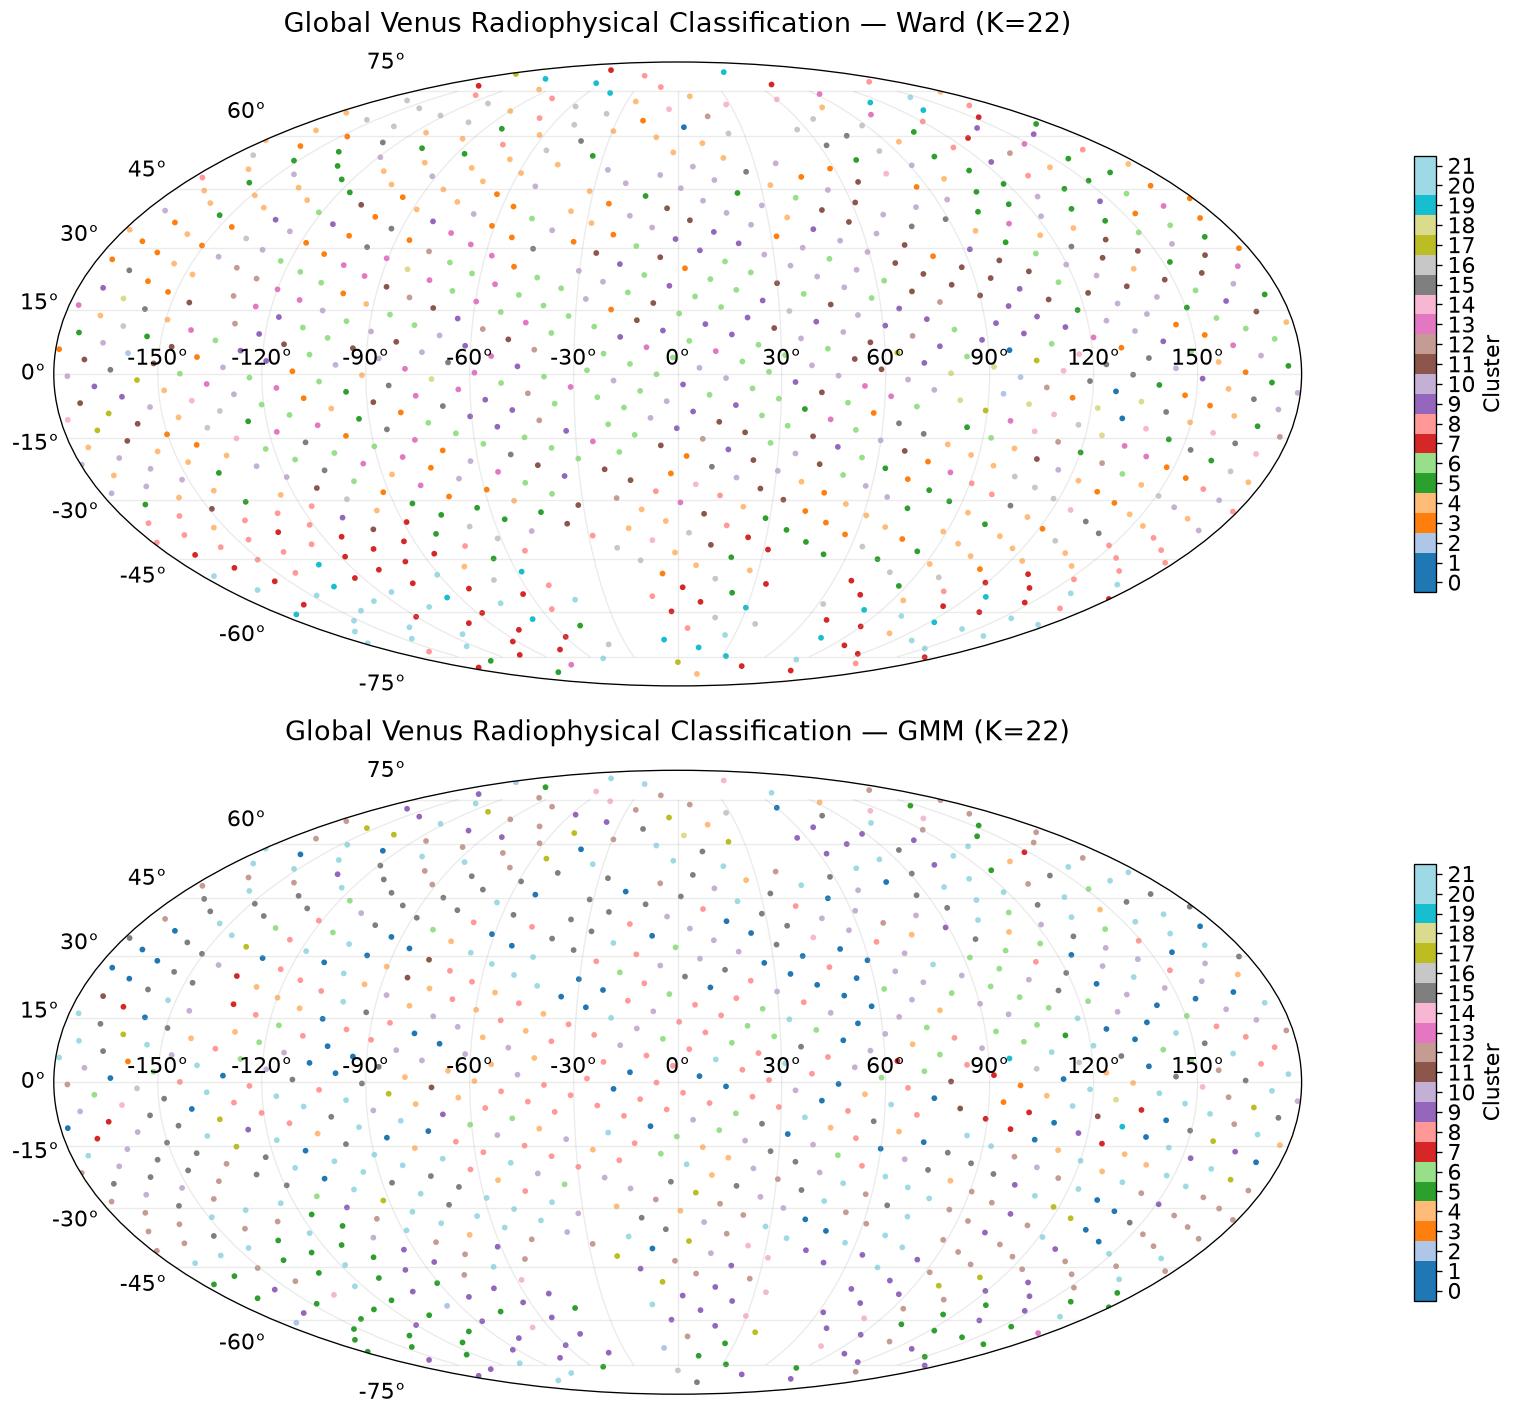

In [17]:
fig = plt.figure(figsize=(16, 12))

methods = [
    ("Ward", "Ward_Cluster"),
    ("GMM", "GMM_Cluster")
]

for i, (title, column) in enumerate(methods):

    ax = fig.add_subplot(
        2, 1, i + 1,
        projection="mollweide"
    )

    sc = ax.scatter(
        np.deg2rad(df_train["Longitude"]),
        np.deg2rad(df_train["Latitude"]),
        c=df_train[column],
        cmap=plt.get_cmap("tab20", K),
        vmin=-0.5,
        vmax=K-0.5,
        s=6,
        rasterized=True
    )

    ax.grid(alpha=0.25)

    ax.set_title(
        f"Global Venus Radiophysical Classification — {title} (K={K})",
        fontsize=16,
        pad=18
    )

    cb = fig.colorbar(
        sc,
        ax=ax,
        ticks=np.arange(K),
        shrink=0.7,
        pad=0.06
    )

    cb.set_label("Cluster")

plt.tight_layout()
plt.show()